## Inicializando dependencias

In [1]:
%run "../3 - Gold/gold_Cadastro.ipynb" # chama tabela gold cadastro

In [2]:
%run "../3 - Gold/gold_Compras.ipynb"  # chama tabela gold compras

In [3]:
%run "../3 - Gold/gold_Perdas.ipynb" # chama tabela gold Perdas

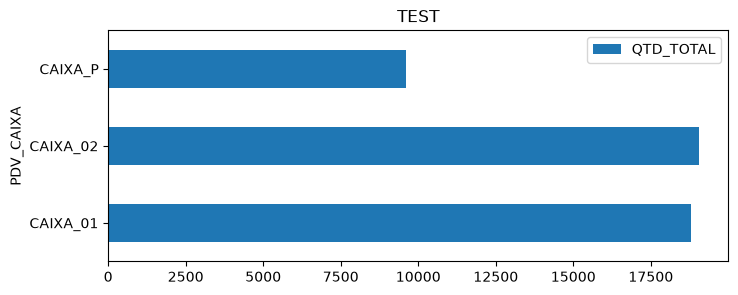

Transações com mais de uma linha: 0
Máximo de valores distintos por transação: 1
Linhas com diferença > 0,01: 4545
  STATUS_VENDA      VALOR  LINHAS
0       ABERTO       0.00    2247
1    CANCELADA       0.00    2226
2    CONCLUIDA  645052.34    9051
3    ESTORNADA       0.00    2298
       ID_TRANSACAO DATA_HORA_VENDA PDV_CAIXA  OPERADOR  COD_PRODUTO  \
0            900001      2026-01-01   CAIXA_P   JULIANA        503.0   
1            900002      2026-01-01  CAIXA_02  PATRICIA    1000001.0   
2            900003      2026-01-01  CAIXA_02  PATRICIA        404.0   
3            900004      2026-01-01  CAIXA_02  PATRICIA        303.0   
4            900005      2026-01-01  CAIXA_02  PATRICIA        304.0   
...             ...             ...       ...       ...          ...   
15817        915818      31/03/2026  CAIXA_01   JULIANA        501.0   
15818        915819      31/03/2026  CAIXA_01   JULIANA        301.0   
15819        915820      31/03/2026  CAIXA_02  PATRICIA    1000001.

In [4]:
%run "../3 - Gold/gold_Vendas.ipynb" # chama tabela gold Vendas

## Mostra Tabelas

In [5]:
gold_Cadastro.head(25)

,COD_PROD,CATEGORIA_BRUTA,NOME_PRODUTO,VENDA_CADASTRO,CUSTO_VENDA,MARGEM,PROD,MEDIDA,UNIDADE
0,101,HORTIFRUTI,TOMATE DEBORA KG,7.90,3.2,4.70,TOMATE DEBORA,1,KG
1,102,HORTIFRUTI,BANANA PRATA KG,5.50,2.1,3.40,BANANA PRATA,1,KG
2,103,HORTIFRUTI,ALFACE AMERICANA UN,3.50,1.2,2.30,ALFACE AMERICANA,1,UN
3,104,HORTIFRUTI,BATATA MONALISA KG,5.90,2.5,3.40,BATATA MONALISA,1,KG
4,105,HORTIFRUTI,CEBOLA NACIONAL KG,0.00,2.8,-2.80,CEBOLA NACIONA,1,L
5,201,ACOUGUE,PICANHA BOV RESFRIADA KG,79.90,42.0,37.90,PICANHA BOV RESFRIADA,1,KG
6,202,ACOUGUE,ALCATRA C/ MAMINHA KG,44.90,26.0,18.90,ALCATRA C/ MAMINHA,1,KG
7,203,ACOUGUE,CARNE MOIDA DE 2A KG,29.90,14.0,15.90,CARNE MOIDA DE 2A,1,KG
8,204,ACOUGUE,LINGUICA TOSCANA KG,22.90,12.0,10.90,LINGUICA TOSCANA,1,KG
9,204,ACOUGUE,LINGUICA TOSCANA KG,22.90,12.0,10.90,LINGUICA TOSCANA,1,KG


In [6]:
gold_Cadastro['COD_PROD'].duplicated().value_counts()

COD_PROD
False    22
True      1
Name: count, dtype: int64

In [7]:
s = gold_Cadastro['COD_PROD']

print("dtype:", s.dtype)
print("nulos:", s.isna().sum())
print("zeros:", (s == 0).sum())
print("texto 'NaN' ou vazio:", (s.astype(str).isin(['NaN', 'nan', ''])).sum())
print("repetidos:", s[s.duplicated(keep=False)].tolist())

print("\nLinhas com código repetido:")
print(gold_Cadastro[s.duplicated(keep=False)][['COD_PROD', 'NOME_PRODUTO', 'CATEGORIA_BRUTA']])

print("\nLinhas com código nulo:")
print(gold_Cadastro[s.isna()][['COD_PROD', 'NOME_PRODUTO', 'CATEGORIA_BRUTA']])

dtype: int64
nulos: 0
zeros: 0
texto 'NaN' ou vazio: 0
repetidos: [204, 204]

Linhas com código repetido:
   COD_PROD         NOME_PRODUTO CATEGORIA_BRUTA
8       204  LINGUICA TOSCANA KG         ACOUGUE
9       204  LINGUICA TOSCANA KG         ACOUGUE

Linhas com código nulo:
Empty DataFrame
Columns: [COD_PROD, NOME_PRODUTO, CATEGORIA_BRUTA]
Index: []


In [8]:
GoldVendasValidas['TOTAL_PAGO'].value_counts()

TOTAL_PAGO
78.60     8
37.30     7
8.40      6
11.80     6
51.60     6
         ..
40.98     1
16.54     1
114.12    1
105.65    1
65.07     1
Name: count, Length: 6165, dtype: int64

In [9]:
GoldVendas['TOTAL_PAGO'].value_counts()

TOTAL_PAGO
0.00      6771
78.60        8
37.30        7
8.40         6
11.80        6
          ... 
40.98        1
16.54        1
114.12       1
105.65       1
65.07        1
Name: count, Length: 6166, dtype: int64

In [10]:
dup = gold_Cadastro[gold_Cadastro['COD_PROD'] == 204]
print(dup.T)
print("linhas idênticas:", dup.drop_duplicates().shape[0] == 1)

f204 = g_cod.loc[g_cod['COD_PRODUTO'] == 204, 'FATURAMENTO'].sum()
print("faturamento do 204:", round(f204, 2))
print("excesso esperado em Vendas_graf:", round(f204, 2))
print("diferença real:", round(GoldVendasValidas['TOTAL_PAGO'].sum() - GoldVendas['TOTAL_PAGO'].sum(), 2))

                                   8                    9
COD_PROD                         204                  204
CATEGORIA_BRUTA              ACOUGUE              ACOUGUE
NOME_PRODUTO     LINGUICA TOSCANA KG  LINGUICA TOSCANA KG
VENDA_CADASTRO                  22.9                 22.9
CUSTO_VENDA                     12.0                 12.0
MARGEM                          10.9                 10.9
PROD                LINGUICA TOSCANA     LINGUICA TOSCANA
MEDIDA                             1                    1
UNIDADE                           KG                   KG
linhas idênticas: True
faturamento do 204: 25992.98
excesso esperado em Vendas_graf: 25992.98
diferença real: 0.0


In [11]:
gold_Cadastro['COD_PROD'].fillna(1000001).astype('Int64')
gold_Cadastro['COD_PROD'].replace(0, 1000001).astype('Int64')

0     101
1     102
2     103
3     104
4     105
5     201
6     202
7     203
8     204
9     204
10    301
11    302
12    303
13    304
14    401
15    402
16    403
17    404
18    501
19    502
20    503
21    601
22    602
Name: COD_PROD, dtype: Int64

In [12]:
gold_Cadastro['COD_PROD'].value_counts() # tabela cadastro produtos

COD_PROD
204    2
101    1
102    1
103    1
104    1
105    1
201    1
202    1
203    1
301    1
302    1
303    1
304    1
401    1
402    1
403    1
404    1
501    1
502    1
503    1
601    1
602    1
Name: count, dtype: int64

In [13]:
GoldComp.head(3)

,NUM_NOTA_FISCAL,DATA_ENTRADA,FORNECEDOR,COD_PROD,QTD_COMPRADA,VALOR_TOTAL_NOTA,RESPONSAVEL_RECEBIMENTO,N_NF,TOTAL_NOTA,DATA,MES,ANO
0,NF-1006,01/01/2026,CEASA SP,101,55,163.39,MATEUS,1006,163.39,2026-01-01,1,2026
1,NF-1046,01/01/2026,CEASA SP,102,119,335.78,THIAGO,1046,335.78,2026-01-01,1,2026
2,NF-1018,01/01/2026,CEASA SP,103,115,243.92,THIAGO,1018,243.92,2026-01-01,1,2026


In [14]:
silverPerdas.head(3) # tabela perdas de produtos / prejuizo

,DATA_OCORRENCIA,SETOR_ORIGEM,DESCRICAO,COD_PROD,QTD_AVARIADA,PREJUIZO_ESTIMADO,RESPONSAVEL,DATA,ANO,MES,V_PREJUIZO
0,01/01/2026,DEPOSITO,FALTA DE MERCADORIA NO ESTOQUE - SUSPEITA FURTO,601.0,1.10,"R$ 14,18",DIEGO,2026-01-01,2026,1,14.18
1,03/01/2026,HORTI,PODRE DESCARTADO NO LIXO,601.0,6.92,"R$ 100,71",BETAO,2026-01-03,2026,1,100.71
2,04/01/2026,AÇOUGUE,LATA AMASSADA NO DESCARREGAMENTO,1000001.0,7.95,"R$ 98,53",BETAO,2026-01-04,2026,1,98.53


In [15]:
g_id.head(3) # tabela vendas por ID

,ID_TRANSACAO,QTD_VENDIDA,FATURAMENTO,TRANSACOES,PRECO_MEDIO
0,900001,5.0,19.70,1,3.94
1,900002,2.0,68.94,1,34.47
2,900003,4.0,129.28,1,32.32


In [16]:
g_caixa.head(3) # tabela vendas por caixa

,PDV_CAIXA,FATURAMENTO,QTD_VENDIDA,TRANSACOES,PRECO_MEDIO,TICKET_MEDIO
1,CAIXA_02,262752.77,11122.0,3695,23.624597,71.110357
0,CAIXA_01,253815.99,10780.0,3566,23.545083,71.176666
2,CAIXA_P,128483.58,5400.0,1790,23.793256,71.778536


In [17]:
g_operador.head(3)

,OPERADOR,FATURAMENTO,QTD_VENDIDA,TRANSACOES,PRECO_MEDIO,TICKET_MEDIO
1,JULIANA,362366.23,15365.0,5094,23.583874,71.135891
3,PATRICIA,249150.73,10545.0,3499,23.627381,71.206268
0,CARLOS_GER,12033.08,497.0,159,24.211429,75.679748


In [18]:
g_cod.head(3) #tabela vendas por produtos

,COD_PRODUTO,FATURAMENTO,QTD_VENDIDA,TRANSACOES,PRECO_MEDIO,TICKET_MEDIO
23,1000001.0,49226.59,2133.0,706,23.078570,69.726048
1,102.0,29890.43,1196.0,391,24.991998,76.446113
5,201.0,29389.40,1255.0,414,23.417849,70.988889


In [19]:
g_forma_pagamento.head(3)

,FORMA_PAGTO,FATURAMENTO,QTD_VENDIDA,TRANSACOES,PRECO_MEDIO,TICKET_MEDIO
5,PIX,157374.09,6618.0,2219,23.779705,70.921176
1,CARTAO_DEB,84828.50,3576.0,1146,23.721616,74.021379
3,FIADO_CADERNETO,84340.32,3507.0,1184,24.049136,71.233378


In [20]:
g_status.head(3) #tabela venddas por status

,STATUS_VENDA,QTD_VENDIDA,PRECO_UNIT_COBRADO,TOTAL_PAGO
0,ABERTO,6748.0,52637.00,0.00
1,CANCELADA,6525.0,0.00,0.00
2,CONCLUIDA,27302.0,212733.18,645052.34


In [21]:
g_ano.head(3) # dados vendas no ano (3 mes)

,ANO,FATURAMENTO,QTD_VENDIDA,TRANSACOES,PRECO_MEDIO,TICKET_MEDIO
0,2026,645052.34,27302.0,9051,23.62656,71.268627


In [22]:
g_mes.head(3) # tabela vendas por mes

,ANO,MES,FATURAMENTO,QTD_VENDIDA,TRANSACOES,PRECO_MEDIO,TICKET_MEDIO
2,2026,3,188314.40,7827.0,2604,24.059589,72.317358
0,2026,1,177091.79,7575.0,2539,23.378454,69.748637
1,2026,2,154554.71,6559.0,2162,23.563761,71.486915


----

## Cria nova tabela

In [23]:
gold_Cadastro['CATEGORIA_BRUTA'].value_counts()

CATEGORIA_BRUTA
HORTIFRUTI            5
ACOUGUE               5
FRIOS E LATICINIOS    4
SECOS E MOLHADOS      3
BEBIDAS               3
PADARIA               2
MERCEARIA             1
Name: count, dtype: int64

In [24]:
print(g_cod.columns.tolist())
print(gold_Cadastro.columns.tolist())

['COD_PRODUTO', 'FATURAMENTO', 'QTD_VENDIDA', 'TRANSACOES', 'PRECO_MEDIO', 'TICKET_MEDIO']
['COD_PROD', 'CATEGORIA_BRUTA', 'NOME_PRODUTO', 'VENDA_CADASTRO', 'CUSTO_VENDA', 'MARGEM', 'PROD', 'MEDIDA', 'UNIDADE']


In [25]:
LocalizaProd = g_cod.merge(
    gold_Cadastro,
    left_on='COD_PRODUTO',
    right_on='COD_PROD',
    how='right'
)

In [26]:
LocalizaProd.head(3)

,COD_PRODUTO,FATURAMENTO,QTD_VENDIDA,TRANSACOES,PRECO_MEDIO,TICKET_MEDIO,COD_PROD,CATEGORIA_BRUTA,NOME_PRODUTO,VENDA_CADASTRO,CUSTO_VENDA,MARGEM,PROD,MEDIDA,UNIDADE
0,101.0,25935.86,1077.0,349,24.081578,74.314785,101,HORTIFRUTI,TOMATE DEBORA KG,7.9,3.2,4.7,TOMATE DEBORA,1,KG
1,102.0,29890.43,1196.0,391,24.991998,76.446113,102,HORTIFRUTI,BANANA PRATA KG,5.5,2.1,3.4,BANANA PRATA,1,KG
2,103.0,26014.99,1082.0,371,24.043429,70.121267,103,HORTIFRUTI,ALFACE AMERICANA UN,3.5,1.2,2.3,ALFACE AMERICANA,1,UN


In [27]:
LocalizaProd1 = gold_Cadastro.merge(
    g_cod,
    left_on='COD_PROD',
    right_on='COD_PRODUTO',
    how='right'
)

In [28]:
LocalizaProd1.head(3)

,COD_PROD,CATEGORIA_BRUTA,NOME_PRODUTO,VENDA_CADASTRO,CUSTO_VENDA,MARGEM,PROD,MEDIDA,UNIDADE,COD_PRODUTO,FATURAMENTO,QTD_VENDIDA,TRANSACOES,PRECO_MEDIO,TICKET_MEDIO
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1000001.0,49226.59,2133.0,706,23.078570,69.726048
1,102.0,HORTIFRUTI,BANANA PRATA KG,5.5,2.1,3.4,BANANA PRATA,1.0,KG,102.0,29890.43,1196.0,391,24.991998,76.446113
2,201.0,ACOUGUE,PICANHA BOV RESFRIADA KG,79.9,42.0,37.9,PICANHA BOV RESFRIADA,1.0,KG,201.0,29389.40,1255.0,414,23.417849,70.988889


In [29]:
LocalizaProd1 = LocalizaProd1.drop(columns=['COD_PRODUTO','NOME_PRODUTO'])

In [30]:
LocalizaProd1.head(3)

,COD_PROD,CATEGORIA_BRUTA,VENDA_CADASTRO,CUSTO_VENDA,MARGEM,PROD,MEDIDA,UNIDADE,FATURAMENTO,QTD_VENDIDA,TRANSACOES,PRECO_MEDIO,TICKET_MEDIO
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,49226.59,2133.0,706,23.078570,69.726048
1,102.0,HORTIFRUTI,5.5,2.1,3.4,BANANA PRATA,1.0,KG,29890.43,1196.0,391,24.991998,76.446113
2,201.0,ACOUGUE,79.9,42.0,37.9,PICANHA BOV RESFRIADA,1.0,KG,29389.40,1255.0,414,23.417849,70.988889


In [31]:
# LocalizaProd1['v_unitario'] = LocalizaProd1['TOTAL_PAGO'] / LocalizaProd1['QTD_VENDIDA']

In [32]:
LocalizaProd1.head(3)

,COD_PROD,CATEGORIA_BRUTA,VENDA_CADASTRO,CUSTO_VENDA,MARGEM,PROD,MEDIDA,UNIDADE,FATURAMENTO,QTD_VENDIDA,TRANSACOES,PRECO_MEDIO,TICKET_MEDIO
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,49226.59,2133.0,706,23.078570,69.726048
1,102.0,HORTIFRUTI,5.5,2.1,3.4,BANANA PRATA,1.0,KG,29890.43,1196.0,391,24.991998,76.446113
2,201.0,ACOUGUE,79.9,42.0,37.9,PICANHA BOV RESFRIADA,1.0,KG,29389.40,1255.0,414,23.417849,70.988889


In [33]:
LocalizaProd1['V_MARGEM'] = LocalizaProd1['PRECO_MEDIO'] - LocalizaProd1['CUSTO_VENDA']

In [34]:
LocalizaProd1.head(3)

,COD_PROD,CATEGORIA_BRUTA,VENDA_CADASTRO,CUSTO_VENDA,MARGEM,PROD,MEDIDA,UNIDADE,FATURAMENTO,QTD_VENDIDA,TRANSACOES,PRECO_MEDIO,TICKET_MEDIO,V_MARGEM
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,49226.59,2133.0,706,23.078570,69.726048,NaN
1,102.0,HORTIFRUTI,5.5,2.1,3.4,BANANA PRATA,1.0,KG,29890.43,1196.0,391,24.991998,76.446113,22.891998
2,201.0,ACOUGUE,79.9,42.0,37.9,PICANHA BOV RESFRIADA,1.0,KG,29389.40,1255.0,414,23.417849,70.988889,-18.582151


----

## Crie tabela para grafico

In [35]:
Vendas_graf = LocalizaProd1[['COD_PROD', 'CATEGORIA_BRUTA', 'PROD', 'QTD_VENDIDA', 'FATURAMENTO','CUSTO_VENDA', 'V_MARGEM', 'PRECO_MEDIO']].copy()

In [36]:
Vendas_graf.head(5)

,COD_PROD,CATEGORIA_BRUTA,PROD,QTD_VENDIDA,FATURAMENTO,CUSTO_VENDA,V_MARGEM,PRECO_MEDIO
0,NaN,NaN,NaN,2133.0,49226.59,NaN,NaN,23.078570
1,102.0,HORTIFRUTI,BANANA PRATA,1196.0,29890.43,2.1,22.891998,24.991998
2,201.0,ACOUGUE,PICANHA BOV RESFRIADA,1255.0,29389.40,42.0,-18.582151,23.417849
3,104.0,HORTIFRUTI,BATATA MONALISA,1205.0,28955.76,2.5,21.529676,24.029676
4,403.0,SECOS E MOLHADOS,OLEO DE SOJA,1232.0,28700.22,4.5,18.795633,23.295633


In [37]:
Valida_Faturamento = Vendas_graf.groupby('COD_PROD')['FATURAMENTO'].sum()
Valida_Faturamento.head(5)

COD_PROD
101.0    25935.86
102.0    29890.43
103.0    26014.99
104.0    28955.76
105.0    27966.61
Name: FATURAMENTO, dtype: float64

In [38]:
margem_cat = Vendas_graf.groupby('CATEGORIA_BRUTA', as_index=False).agg(
    MARGEM_TOTAL=('V_MARGEM', 'sum'),
    FATURAMENTO=('FATURAMENTO', 'sum'),
)
margem_cat.head()

,CATEGORIA_BRUTA,MARGEM_TOTAL,FATURAMENTO
0,ACOUGUE,8.601315,127173.86
1,BEBIDAS,61.413269,76242.36
2,FRIOS E LATICINIOS,46.160366,102601.99
3,HORTIFRUTI,109.986867,138763.65
4,MERCEARIA,12.324680,24229.70


In [39]:
margem_cat['MARGEM_PERC'] = margem_cat['MARGEM_TOTAL'] / margem_cat['FATURAMENTO']

In [40]:
margem_cat['MARGEM_PERC'].head(5)

0    0.000068
1    0.000806
2    0.000450
3    0.000793
4    0.000509
Name: MARGEM_PERC, dtype: float64

In [41]:
Vendas_graf['PRECO_MEDIO'].value_counts()

PRECO_MEDIO
23.673024    2
23.078570    1
24.991998    1
23.417849    1
24.029676    1
23.295633    1
24.702317    1
24.640185    1
24.341360    1
23.999826    1
23.596440    1
24.043429    1
24.081578    1
23.749036    1
23.850856    1
23.703767    1
23.577557    1
23.662587    1
23.623295    1
23.824680    1
21.628638    1
22.208780    1
22.712573    1
22.595407    1
Name: count, dtype: int64

In [42]:
sem_cadastro = Vendas_graf[Vendas_graf['CATEGORIA_BRUTA'].isna()]
print("Faturamento sem cadastro:", sem_cadastro['FATURAMENTO'].sum())

Faturamento sem cadastro: 71460.47


In [43]:
assert abs(Vendas_graf['PRECO_MEDIO'].sum() - GoldVendasValidas['TOTAL_PAGO'].sum())

In [44]:
Vendas_graf.head(3)

,COD_PROD,CATEGORIA_BRUTA,PROD,QTD_VENDIDA,FATURAMENTO,CUSTO_VENDA,V_MARGEM,PRECO_MEDIO
0,NaN,NaN,NaN,2133.0,49226.59,NaN,NaN,23.078570
1,102.0,HORTIFRUTI,BANANA PRATA,1196.0,29890.43,2.1,22.891998,24.991998
2,201.0,ACOUGUE,PICANHA BOV RESFRIADA,1255.0,29389.40,42.0,-18.582151,23.417849


### Cria um grafico para produto x margem

<Axes: ylabel='PROD'>

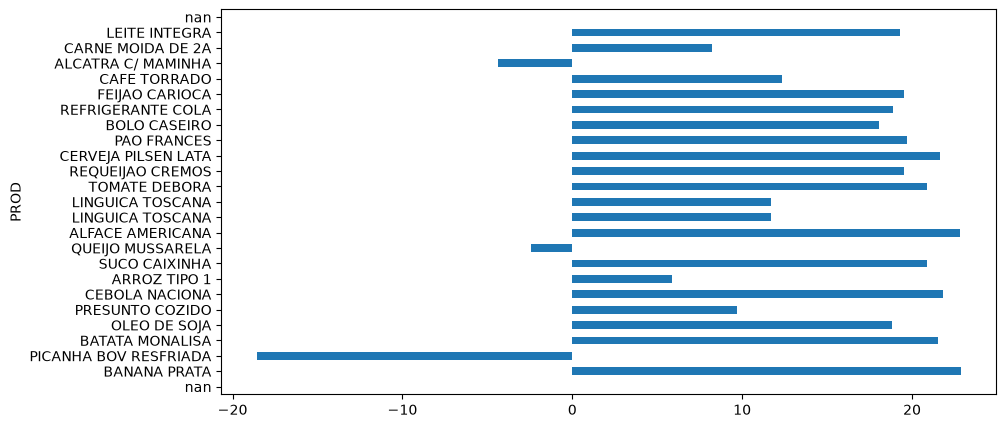

In [45]:
Vendas_graf.plot(
    kind='barh',
    x='PROD',
    y='V_MARGEM',
    figsize=(10, 5),
    legend=False
)

<Axes: ylabel='CATEGORIA_BRUTA'>

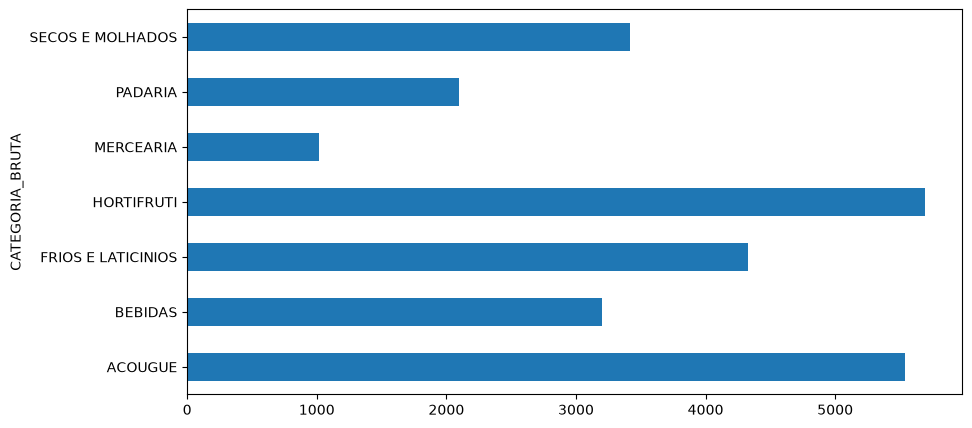

In [46]:
Cons_qtd = Vendas_graf.groupby(
    'CATEGORIA_BRUTA',
    as_index=False
)['QTD_VENDIDA'].sum()

Cons_qtd.plot(
    kind='barh',
    x='CATEGORIA_BRUTA',
    y='QTD_VENDIDA',
    figsize=(10, 5),
    legend=False
)

### Cria um grafico para cat x total

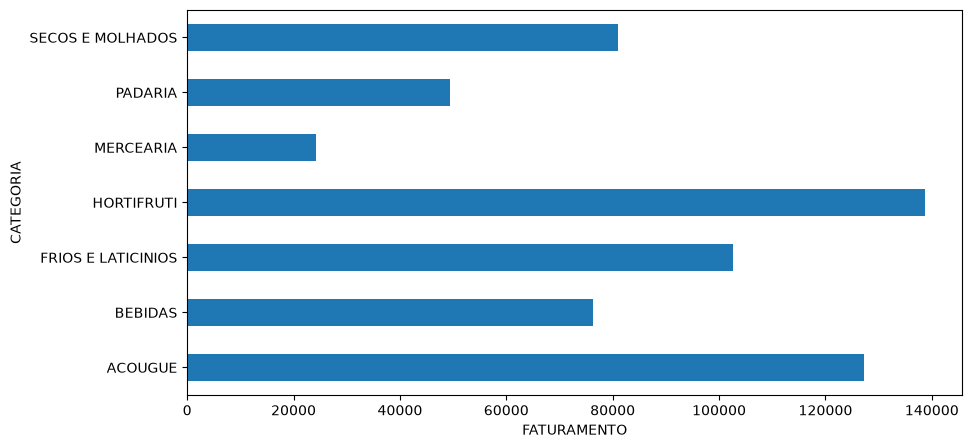

In [47]:
Cons_Unitario = Vendas_graf.groupby(
    'CATEGORIA_BRUTA',
    as_index=False
)['FATURAMENTO'].sum()


Cons_Unitario.plot(
    kind='barh',
    x='CATEGORIA_BRUTA',
    y='FATURAMENTO',
    figsize=(10, 5),
    legend=False
)

plt.xlabel('FATURAMENTO')
plt.ylabel('CATEGORIA')
plt.show()

### Cria um grafico para cat x a média da margem de lucro

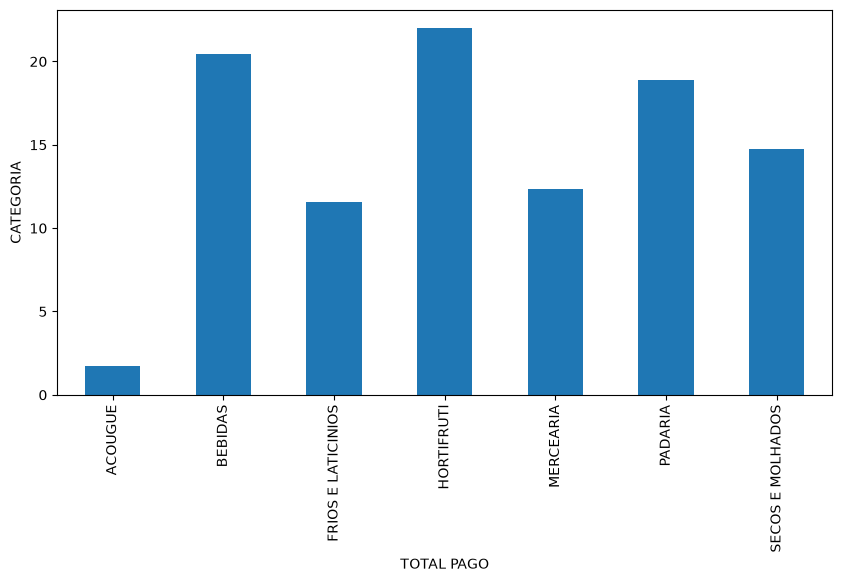

In [48]:
Cons_Unitario_2 = Vendas_graf.groupby(
    'CATEGORIA_BRUTA',
    as_index=False
)['V_MARGEM'].mean()


Cons_Unitario_2.plot(
    kind='bar',
    x='CATEGORIA_BRUTA',
    y='V_MARGEM',
    figsize=(10, 5),
    legend=False
)

plt.xlabel('TOTAL PAGO')
plt.ylabel('CATEGORIA')
plt.show()

### Cria um grafico para cat x total

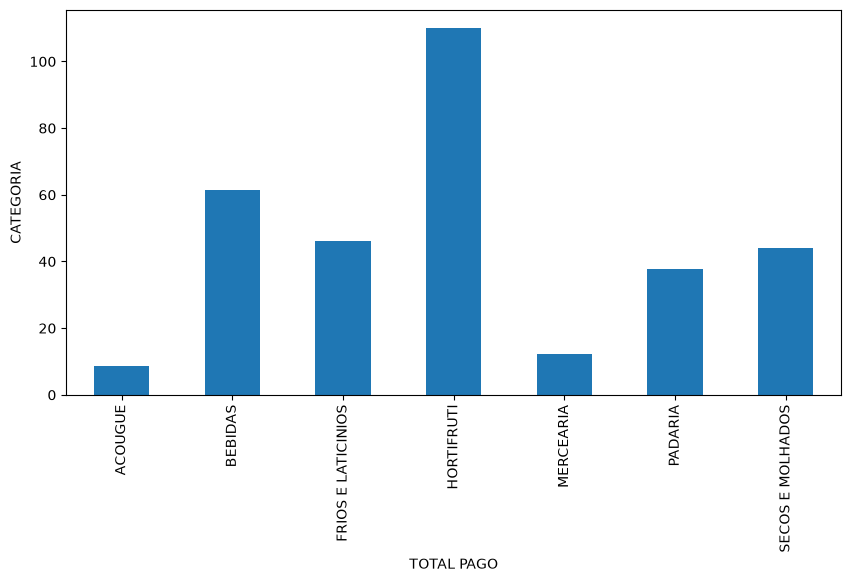

In [49]:
Cons_Unitario_2 = Vendas_graf.groupby(
    'CATEGORIA_BRUTA',
    as_index=False
)['V_MARGEM'].sum()


Cons_Unitario_2.plot(
    kind='bar',
    x='CATEGORIA_BRUTA',
    y='V_MARGEM',
    figsize=(10, 5),
    legend=False
)

plt.xlabel('TOTAL PAGO')
plt.ylabel('CATEGORIA')
plt.show()